In [18]:
import pandas as pd

prices = pd.Series([100, 102, 99, 101, 104], index=pd.date_range("2024-01-01", periods=5))
signal = pd.Series([1, 1, 0, 1, 1], index=prices.index)

market_return = prices.pct_change().fillna(0)
position = signal.shift(1).fillna(0).astype(int)
strategy_return = market_return * position

pd.DataFrame({
    "price": prices,
    "signal": signal,
    "position": position,
    "market": market_return,
    "strategy": strategy_return,
})

,price,signal,position,market,strategy
2024-01-01,100,1,0,0.000000,0.000000
2024-01-02,102,1,1,0.020000,0.020000
2024-01-03,99,0,1,-0.029412,-0.029412
2024-01-04,101,1,0,0.020202,0.000000
2024-01-05,104,1,1,0.029703,0.029703


In [19]:
from backtester.data import load_prices
from backtester.strategy import sma_crossover

spy = load_prices('SPY', '2015-01-01', '2026-01-01')
signals = sma_crossover(spy['Adj Close'])

market_returns = spy['Adj Close'].pct_change().fillna(0)
positions = signals.shift(1).fillna(0).astype(int)
strategy_returns = market_returns * positions

results = pd.DataFrame({
    "price": spy['Adj Close'],
    "signal": signals,
    "position": positions,
    "market": market_returns,
    "strategy": strategy_returns,
})

results.loc['2020-02-28':'2020-03-06']

Loaded SPY from cache: SPY_2015-01-01_2026-01-01.csv


,price,signal,position,market,strategy
Date,,,,,
2020-02-28,269.377930,1,1,-0.004201,-0.004201
2020-03-02,281.043579,1,1,0.043306,0.043306
2020-03-03,272.996765,0,1,-0.028632,-0.028632
2020-03-04,284.471527,0,0,0.042033,0.000000
2020-03-05,275.015167,0,0,-0.033242,-0.000000
2020-03-06,270.468903,0,0,-0.016531,-0.000000


In [20]:
cost_rate = 0.001

trades = positions.diff().abs().fillna(0)
cost = trades * cost_rate
net_return = strategy_returns - cost

pd.DataFrame({
    "position": positions,
    "trades": trades,
    "cost": cost,
    "strategy": strategy_returns,
    "net": net_return,
})

,position,trades,cost,strategy,net
Date,,,,,
2015-01-02,0,0.0,0.0,0.000000,0.000000
2015-01-05,0,0.0,0.0,-0.000000,-0.000000
2015-01-06,0,0.0,0.0,-0.000000,-0.000000
2015-01-07,0,0.0,0.0,0.000000,0.000000
2015-01-08,0,0.0,0.0,0.000000,0.000000
...,...,...,...,...,...
2025-12-24,1,0.0,0.0,0.003518,0.003518
2025-12-26,1,0.0,0.0,-0.000101,-0.000101
2025-12-29,1,0.0,0.0,-0.003564,-0.003564


In [21]:
results["trades"] = results["position"].diff().abs().fillna(0)
results["cost"] = results["trades"] * cost_rate
results["net"] = results["strategy"] - results["cost"]

In [22]:
results["trades"].sum()

np.float64(51.0)

In [23]:
results["cost"].sum()

np.float64(0.051000000000000004)

In [24]:
results.loc["2016-05-25":"2016-06-01"]

,price,signal,position,market,strategy,trades,cost,net
Date,,,,,,,,
2016-05-25,176.905899,1,1,0.006783,0.006783,0.0,0.000,0.006783
2016-05-26,176.956604,0,1,0.000287,0.000287,0.0,0.000,0.000287
2016-05-27,177.717453,1,0,0.004300,0.000000,1.0,0.001,-0.001000
2016-05-31,177.379257,1,1,-0.001903,-0.001903,1.0,0.001,-0.002903
2016-06-01,177.742737,1,1,0.002049,0.002049,0.0,0.000,0.002049


In [25]:
initial_capital = 10_000

equity = initial_capital * (1 + net_return).cumprod()
benchmark = initial_capital * (1 + market_returns).cumprod()

pd.DataFrame({
    "net": net_return,
    "growth": (1 + net_return),
    "equity": equity,
    "market": market_returns,
    "benchmark": benchmark,
})


,net,growth,equity,market,benchmark
Date,,,,,
2015-01-02,0.000000,1.000000,10000.000000,0.000000,10000.000000
2015-01-05,-0.000000,1.000000,10000.000000,-0.018059,9819.406886
2015-01-06,-0.000000,1.000000,10000.000000,-0.009419,9726.914372
2015-01-07,0.000000,1.000000,10000.000000,0.012461,9848.124702
2015-01-08,0.000000,1.000000,10000.000000,0.017745,10022.878157
...,...,...,...,...,...
2025-12-24,0.003518,1.003518,22938.547005,0.003518,40470.234057
2025-12-26,-0.000101,0.999899,22936.221169,-0.000101,40466.130610
2025-12-29,-0.003564,0.996436,22854.483794,-0.003564,40321.922230


In [26]:
results["equity"] = initial_capital * (1 + results["net"]).cumprod()
results["benchmark"] = initial_capital * (1 + results["market"]).cumprod()
results[["equity", "benchmark"]].iloc[-1]

equity       22657.454066
benchmark    39974.304780
Name: 2025-12-31 00:00:00, dtype: float64

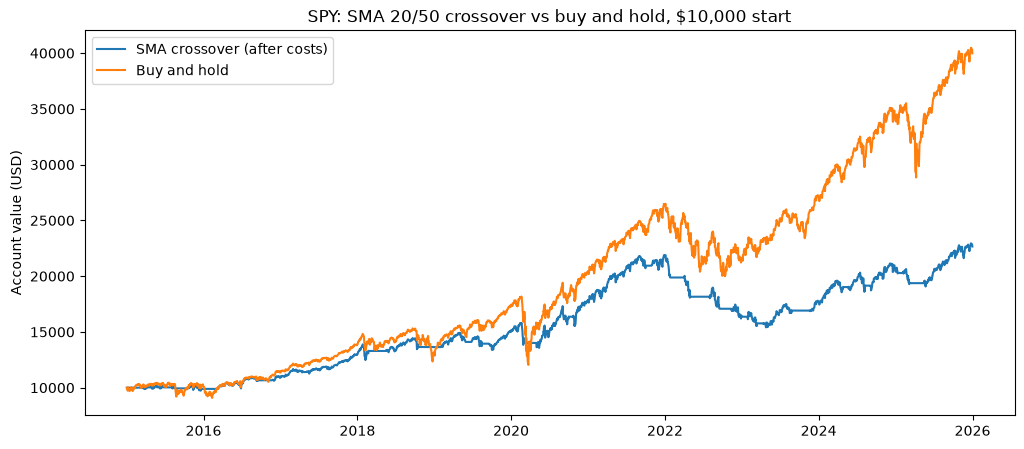

In [27]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(results.index, results["equity"], label="SMA crossover (after costs)")
ax.plot(results.index, results["benchmark"], label="Buy and hold")
ax.set_title("SPY: SMA 20/50 crossover vs buy and hold, $10,000 start")
ax.set_ylabel("Account value (USD)")
ax.legend()
plt.show()

In [28]:
prices = pd.Series([100, 101, 103, 102, 100, 99, 104], index=pd.date_range("2024-01-01", periods=7))
signal = pd.Series([0, 1, 1, 0, 0, 1, 1], index=prices.index)
cost_rate = 0.001

change = signal.diff()
entries = list(signal.index[change == 1])
exits = list(signal.index[change == -1])

if len(entries) > len(exits):
    exits.append(signal.index[-1])

trade_log = pd.DataFrame({"entry_date": entries, "exit_date": exits})
trade_log["entry_price"] = prices.loc[entries].to_numpy()
trade_log["exit_price"] = prices.loc[exits].to_numpy()
trade_log["days_held"] = (trade_log["exit_date"] - trade_log["entry_date"]).dt.days
trade_log["net_return"] = trade_log["exit_price"] / trade_log["entry_price"] - 1 - 2 * cost_rate

trade_log.round({"net_return": 4})

,entry_date,exit_date,entry_price,exit_price,days_held,net_return
0,2024-01-02,2024-01-04,101,102,2,0.0079
1,2024-01-06,2024-01-07,99,104,1,0.0485


In [29]:
changes = signals.diff()
entries = list(signals.index[changes == 1])
exits = list(signals.index[changes == -1])

if len(entries) > len(exits):
    exits.append(signals.index[-1])

trade_log = pd.DataFrame({"entry_date": entries, "exit_date": exits})
trade_log["entry_price"] = spy["Adj Close"].loc[entries].to_numpy()
trade_log["exit_price"] = spy["Adj Close"].loc[exits].to_numpy()
trade_log["days_held"] = (trade_log["exit_date"] - trade_log["entry_date"]).dt.days
trade_log["net_return"] = trade_log["exit_price"] / trade_log["entry_price"] - 1 - 2 * cost_rate

trade_log.round({"entry_price": 2, "exit_price": 2, "net_return": 4})

,entry_date,exit_date,entry_price,exit_price,days_held,net_return
0,2015-03-16,2015-04-20,171.86,173.68,35,0.0086
1,2015-04-24,2015-06-25,175.17,174.53,62,-0.0056
2,2015-08-03,2015-08-19,174.48,173.25,16,-0.0090
3,2015-10-22,2015-12-22,171.60,171.14,61,-0.0047
4,2016-03-09,2016-05-26,167.67,176.96,78,0.0534
5,2016-05-27,2016-09-19,177.72,182.25,115,0.0235
6,2016-11-21,2017-04-19,188.01,201.40,149,0.0693
7,2017-05-03,2017-09-07,205.75,214.03,127,0.0382
8,2017-09-08,2018-02-23,213.78,240.57,168,0.1233
9,2018-05-15,2018-10-18,238.36,245.22,156,0.0268


In [30]:
initial_capital * (1 + trade_log["net_return"]).prod()

np.float64(22670.171666469174)

In [31]:
trade_log.sort_values("net_return").head(3)

,entry_date,exit_date,entry_price,exit_price,days_held,net_return
16,2022-04-01,2022-05-02,426.426086,390.234680,31,-0.086871
17,2022-08-01,2022-09-16,388.412262,366.072083,46,-0.059517
15,2021-10-28,2022-01-25,428.667786,407.788483,89,-0.050707


In [32]:
from backtester.backtest import run_backtest, extract_trades

bt = run_backtest(spy["Adj Close"], signals)
pd.testing.assert_series_equal(bt["equity"], results["equity"])

In [33]:
pd.testing.assert_frame_equal(extract_trades(spy["Adj Close"], signals), trade_log)